# 17. Entanglement microscopy with DMRG

**Goal.** Get the reduced density matrix (RDM) of a few neighbouring spins of the two-dimensional transverse-field Ising model from DMRG, check it entry by entry against the quantum Monte Carlo (QMC) tomography of the entanglement-microscopy papers, and compute from it the negativity and the genuine multipartite negativity (GMN) across the phase transition.

*Entanglement microscopy* asks whether a handful of neighbouring sites are entangled *with each other*, not with the rest of the system. That question needs the full RDM $\rho_A$ of the small region $A$. Wang, Song, Lyu, Witczak-Krempa and Meng (*Entanglement microscopy and tomography in many-body systems*, [arXiv:2402.14916](https://arxiv.org/abs/2402.14916); [Nat. Commun. 16, 96 (2025)](https://doi.org/10.1038/s41467-024-55354-z)) obtained it by sampling with QMC every Pauli string on $A$,

$$
\rho_A = \frac{1}{2^n}\sum_{P} \langle P\rangle\, P ,
$$

and Lyu, Song, Wang, Meng and Witczak-Krempa (*Multiparty entanglement microscopy of quantum Ising models in one, two, and three dimensions*, [arXiv:2412.12533](https://arxiv.org/abs/2412.12533); [Phys. Rev. B 111, 245108 (2025)](https://doi.org/10.1103/PhysRevB.111.245108)) extended it to three and four sites. Song, Wang, Lyu, Meng and Witczak-Krempa published the matrices in the repository [songmengh/Ising_RDMs](https://github.com/songmengh/Ising_RDMs); every QMC number below is computed from those files, and the few matrices this notebook needs are copied into `results/microscopy.json`. An MPS holds the same information, so DMRG should give the same matrices. This notebook checks that it does, and finds where it does not.

The papers write the model as $H = -\sum_{\langle ij\rangle} Z_iZ_j - h\sum_i X_i$ on the square lattice, with the quantum critical point at $h_c = 3.044$ (S. Hesselmann and S. Wessel, [arXiv:1602.02096](https://arxiv.org/abs/1602.02096); [Phys. Rev. B 93, 155157 (2016)](https://doi.org/10.1103/PhysRevB.93.155157)). This repo writes $-\sum XX - h\sum Z$. A Hadamard gate on every spin swaps $X$ and $Z$, so `to_zz_basis` turns one convention into the other; every matrix compared below is in the papers' basis.

In [1]:
import json
import logging
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from medt.gmn import gmn, negativity
from tenpy.algorithms import dmrg as tenpy_dmrg
from tenpy.models.tf_ising import TFIModel
from tenpy.networks.mps import MPS

import dmrg_from_scratch as dmrg
from dmrg_from_scratch import microscopy as mic

logging.disable(logging.CRITICAL)
warnings.filterwarnings("ignore")
RES = json.loads(Path("../results/microscopy.json").read_text())

## 1. An RDM from an MPS

The recipe: walk along the chain from the left. At each site of $A$ keep the physical leg open, once on the ket and once on the bra; at every other site sum the two legs together (the partial trace). For a right-canonical MPS everything to the right of $A$ is the identity, so the walk can stop at the last site of $A$. Here it is on a 12-site Ising chain, checked against the RDM of the exact ground state:

In [2]:
L, h = 12, 1.0
r = dmrg.dmrg(dmrg.tfim_mpo(L, h), chi_max=32, n_sweeps=4)
E0, psi0 = dmrg.ground_state(dmrg.tfim_cylinder(1, Lx=L, h=h))  # a cylinder of width 1 is the chain
for sites in [(5, 6), (5, 7), (4, 5, 6, 7)]:
    rho = mic.segment_rdm(r["mps"], sites)
    diff = np.abs(rho - mic.dense_rdm(psi0, sites, L)).max()
    print(f"sites {sites}: largest difference from the exact RDM = {diff:.1e}")

sites (5, 6): largest difference from the exact RDM = 1.3e-14
sites (5, 7): largest difference from the exact RDM = 1.2e-14
sites (4, 5, 6, 7): largest difference from the exact RDM = 1.7e-14


QMC cannot contract a wave function, so it measures instead: every Pauli string on $A$, 16 for two sites and 256 for four. Rebuilding $\rho_A$ from those expectation values gives back the same matrix:

In [3]:
rho = mic.segment_rdm(r["mps"], (5, 6))
paulis = mic.pauli_expectations(rho)
print(len(paulis), "Pauli strings; <XX> =", round(paulis["XX"], 6), " <ZI> =", round(paulis["ZI"], 6))
print("rebuilt from them:", np.abs(mic.rdm_from_paulis(paulis) - rho).max())

16 Pauli strings; <XX> = 0.597039  <ZI> = 0.677357
rebuilt from them: 4.163336342344337e-17


## 2. A cylinder, checked exactly

On a cylinder the MPS snakes column by column, so a 2 × 2 plaquette at $(x, y), (x, y+1), (x+1, y), (x+1, y+1)$ sits at MPS sites $s, s+1, s+W, s+W+1$: the walk crosses $W + 2$ sites and traces out the $W - 2$ in between. With TeNPy on a 4 × 4 cylinder (16 spins, small enough for exact diagonalization):

In [4]:
W, Lx, h = 4, 4, 3.0
model = TFIModel({"lattice": "Square", "Lx": Lx, "Ly": W, "bc_x": "open", "bc_y": "periodic",
                  "bc_MPS": "finite", "J": 1.0, "g": h, "conserve": "parity"})
psi = MPS.from_product_state(model.lat.mps_sites(), ["up"] * (W * Lx), bc="finite")
tenpy_dmrg.run(psi, model, {"trunc_params": {"chi_max": 128, "svd_min": 1e-14}, "mixer": True, "max_sweeps": 10})
E0, psi0 = dmrg.ground_state(dmrg.tfim_cylinder(W, Lx=Lx, h=h))

s = W + 1  # the site at x = 1, y = 1
plaquette = [s, s + 1, s + W, s + W + 1]
left, tensors = mic.tenpy_segment(psi, s, s + W + 1)
rho_dmrg = mic.segment_rdm(tensors, [0, 1, W, W + 1], left)
print("plaquette RDM, DMRG against exact:", f"{np.abs(rho_dmrg - mic.dense_rdm(psi0, plaquette, W * Lx)).max():.1e}")

plaquette RDM, DMRG against exact: 1.8e-13


`tenpy_segment` hands over TeNPy's tensors with the Schmidt values on the bond to the left of the segment; their squares are the density matrix of that bond, which replaces everything to the left. (TeNPy's spin basis with a conserved parity is ordered $Z = -1, +1$, the reverse of ours; `tenpy_segment` flips it.)

## 3. The bulk of an infinite cylinder

QMC works on an $L\times L$ torus. The DMRG counterpart is an infinite cylinder of width $W$: iDMRG finds a translation-invariant MPS, and the plaquette RDM comes out the same anywhere along it. A live run at the critical point, width 4:

In [5]:
def plaquette_rdm(W, h, chi):
    model = TFIModel({"lattice": "Square", "Lx": 2, "Ly": W, "bc_x": "periodic", "bc_y": "periodic",
                      "bc_MPS": "infinite", "J": 1.0, "g": h, "conserve": "parity"})
    psi = MPS.from_product_state(model.lat.mps_sites(), ["up"] * (2 * W), bc="infinite")
    tenpy_dmrg.run(psi, model, {"trunc_params": {"chi_max": chi, "svd_min": 1e-12}, "mixer": True,
                                "max_E_err": 1e-9, "max_S_err": 1e-5, "max_sweeps": 20, "max_trunc_err": 1.0})
    left, tensors = mic.tenpy_segment(psi, 0, W + 1)
    return mic.to_zz_basis(mic.segment_rdm(tensors, [0, 1, W, W + 1], left)).real


t = time.perf_counter()
rho4 = plaquette_rdm(4, 3.044, 32)
qmc = next(q for q in RES["qmc"] if q["L"] == 24 and q["h"] == 3.044)
rho_qmc = np.array(qmc["rho"])
print(f"{time.perf_counter() - t:.0f} s; largest difference from QMC (L = 24): {np.abs(rho4 - rho_qmc).max():.1e},"
      f" largest QMC error bar: {qmc['rho_error_max']:.1e}")

3 s; largest difference from QMC (L = 24): 7.3e-03, largest QMC error bar: 3.9e-05


Close, but not within the QMC error bars: a cylinder of width 4 is not the plane. Before going wider, one subtlety. In the ordered phase, $h < h_c$, the plane has two ground states, magnetized up and down. A finite torus, as in QMC, is in their symmetric superposition, the cat state, and its small-region RDM is the equal mixture of the two. iDMRG with the $\mathbb Z_2$ parity conserved is forced into the same symmetric state, so the two RDMs are comparable at every $h$. (Without the conservation DMRG usually picks one broken state; `symmetrize` turns its RDM into the mixture.)

## 4. Entry by entry: widths 4, 6, 8 against QMC

The full runs (iDMRG at $\chi$ = 32, 64, 128 for widths 4 and 6, and 64, 128 for width 8 at five fields; QMC matrices read from the published files) come from `python scripts/make_results.py microscopy` (about 6 minutes on a 12-core laptop; it reads the QMC matrices from GitHub). The largest difference between DMRG and QMC entries, against the size of the QMC error bars and against the change of the QMC matrix from $L = 16$ to $L = 24$:

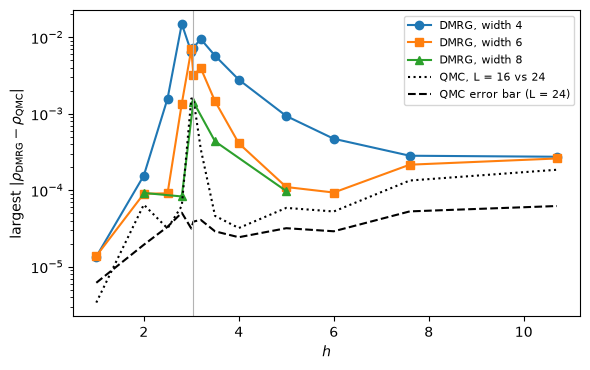

In [6]:
def by(rows, **key):
    return {r["h"]: r for r in rows if all(r[k] == v for k, v in key.items())}


q24, q16 = by(RES["qmc"], L=24), by(RES["qmc"], L=16)
hs = sorted(q24)
fig, ax = plt.subplots(figsize=(6, 3.8))
for W, marker in [(4, "o"), (6, "s"), (8, "^")]:
    d = by(RES["dmrg"], W=W)
    x = sorted(d)
    ax.semilogy(x, [d[h]["runs"][-1]["diff_qmc24"] for h in x], marker + "-", label=f"DMRG, width {W}")
ax.semilogy(hs, [q16[h]["diff_qmc24"] for h in hs], "k:", label="QMC, L = 16 vs 24")
ax.semilogy(hs, [q24[h]["rho_error_max"] for h in hs], "k--", label="QMC error bar (L = 24)")
ax.axvline(3.044, color="0.7", lw=0.8)
ax.set(xlabel="$h$", ylabel=r"largest $|\rho_{\rm DMRG} - \rho_{\rm QMC}|$")
ax.legend(fontsize=8)
fig.tight_layout()

Away from the critical point, widths 6 and 8 reproduce the QMC matrix to about $10^{-4}$, the size of QMC's own error bars and of the change in QMC from $L = 16$ to $24$: the two methods give the same matrix. Near $h_c$ the difference grows to a few $10^{-3}$, shrinking with width (width 8: $1.4\times10^{-3}$ at $h_c$), and QMC moves by about as much from $L = 16$ to $24$. That is the finite-size error both methods have at a critical point, where correlations reach across the whole system. Width 4 is off by $10^{-2}$ near $h = 2.8$: a cylinder that narrow has its own transition at a smaller field. (Convergence in $\chi$, the change from $\chi = 64$ to $128$, is $10^{-4}$ or better everywhere for widths 4 and 6, and up to $10^{-3}$ for width 8 near $h_c$.)

## 5. Negativity and GMN across the transition

From each plaquette RDM, by partial traces:

* the negativity $\mathcal N = (\lVert\rho^{T_1}\rVert_1 - 1)/2$ of a nearest-neighbour pair (G. Vidal and R. F. Werner, [arXiv:quant-ph/0102117](https://arxiv.org/abs/quant-ph/0102117); [Phys. Rev. A 65, 032314 (2002)](https://doi.org/10.1103/PhysRevA.65.032314)), along $y$ (around the cylinder) and along $x$; the papers quote the logarithmic negativity $\ln(2\mathcal N + 1)$, which carries the same information;
* the negativity of the diagonal pair, at distance $\sqrt 2$;
* the GMN of the three-site corner and of the whole plaquette: positive only if the state is not a mixture of states that are each separable across some cut, so it certifies genuine three- or four-party entanglement (B. Jungnitsch, T. Moroder and O. Gühne, [arXiv:1010.6049](https://arxiv.org/abs/1010.6049); [Phys. Rev. Lett. 106, 190502 (2011)](https://doi.org/10.1103/PhysRevLett.106.190502); here the renormalized version of M. Hofmann, T. Moroder and O. Gühne, [arXiv:1401.2424](https://arxiv.org/abs/1401.2424); [J. Phys. A 47, 155301 (2014)](https://doi.org/10.1088/1751-8113/47/15/155301), computed with `medt`).

A live example on the QMC matrix at the critical point:

In [7]:
print("nearest-neighbour negativity:", round(negativity(mic.partial_trace(rho_qmc, [0, 1])), 4))
print("diagonal pair negativity:    ", round(negativity(mic.partial_trace(rho_qmc, [0, 3])), 4) + 0.0)
print("corner GMN:                  ", round(gmn(mic.partial_trace(rho_qmc, [0, 1, 2])), 4))
print("plaquette GMN:               ", round(gmn(rho_qmc), 4))

nearest-neighbour negativity: 0.0567
diagonal pair negativity:     0.0


corner GMN:                   0.0373


plaquette GMN:                0.0549


The full curves, DMRG lines against QMC points (error bars from resampling every matrix element within its quoted error):

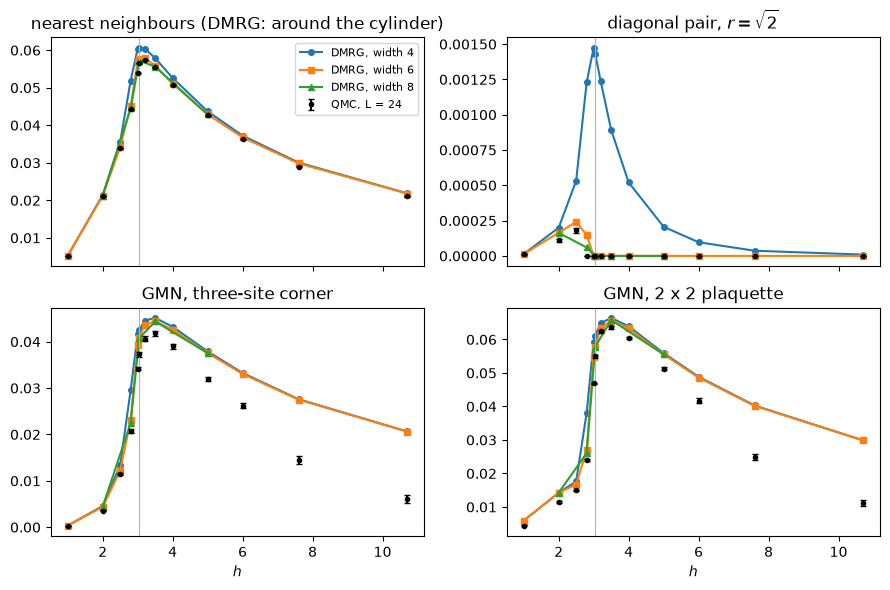

In [8]:
panels = [("N_nn_y", "nearest neighbours (DMRG: around the cylinder)"), ("N_diag", r"diagonal pair, $r = \sqrt{2}$"),
          ("gmn_corner", "GMN, three-site corner"), ("gmn_plaquette", "GMN, 2 x 2 plaquette")]
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
for ax, (key, title) in zip(axes.flat, panels, strict=True):
    for W, marker in [(4, "o"), (6, "s"), (8, "^")]:
        d = by(RES["dmrg"], W=W)
        x = sorted(d)
        ax.plot(x, [d[h]["runs"][-1][key] for h in x], marker + "-", ms=4, label=f"DMRG, width {W}")
    values, errors = [q24[h][key] for h in hs], [q24[h][key + "_error"] for h in hs]
    ax.errorbar(hs, values, errors, fmt="k.", capsize=2, label="QMC, L = 24")
    ax.axvline(3.044, color="0.7", lw=0.8)
    ax.set(title=title)
for ax in axes[1]:
    ax.set(xlabel="$h$")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()

**The comparison in one table.** DMRG on the widest cylinder run at each field (width 8 where it was run, otherwise 6), with its error estimated from the last doubling of $\chi$ and, where both exist, the difference between widths 6 and 8; QMC at $L = 24$ with the resampled error. A number in brackets is the error in the last digit; none means below $10^{-4}$.

In [9]:
def fmt(value, error):
    value = value + 0.0  # no "-0.0000"
    digits = round(error * 1e4)
    return f"{value:.4f}" + (f"({digits})" if digits else "")


d6, d8 = by(RES["dmrg"], W=6), by(RES["dmrg"], W=8)
keys = {"N_nn_y": "NN negativity", "N_diag": "diagonal pair",
        "gmn_corner": "corner GMN", "gmn_plaquette": "plaquette GMN"}
print(f"{'h':>10} | " + " | ".join(f"{name + ', DMRG / QMC':^26}" for name in keys.values()))
for h in [1.0, 2.5, 2.8, 3.044, 3.5, 5.0, 10.7]:
    best = d8.get(h, d6[h])
    last, prev = best["runs"][-1], best["runs"][-2]
    cells = []
    for k in keys:
        err = abs(last[k] - prev[k])
        if h in d8:
            err = max(err, abs(last[k] - d6[h]["runs"][-1][k]))
        cells.append(f"{fmt(last[k], err) + ' / ' + fmt(q24[h][k], q24[h][k + '_error']):^26}")
    label = f"{h:g} (w{best['W']})"
    print(f"{label:>10} | " + " | ".join(cells))

seconds = [d["runs"][-1]["seconds"] for d in RES["dmrg"]]
print(f"\nDMRG cost: {len(seconds)} cylinders, {np.median(seconds):.0f} s each (median, chi up to 128) on a laptop")

         h | NN negativity, DMRG / QMC  | diagonal pair, DMRG / QMC  |   corner GMN, DMRG / QMC   | plaquette GMN, DMRG / QMC 
    1 (w6) |      0.0052 / 0.0052       |      0.0000 / 0.0000       |      0.0003 / 0.0003       |     0.0059 / 0.0044(1)    
  2.5 (w6) |      0.0342 / 0.0340       |      0.0002 / 0.0002       |     0.0122 / 0.0114(2)     |     0.0167 / 0.0150(2)    
  2.8 (w8) |     0.0445(6) / 0.0443     |     0.0001(2) / 0.0000     |   0.0225(6) / 0.0207(4)    |   0.0261(10) / 0.0240(3)  
3.044 (w8) |     0.0573(4) / 0.0567     |      0.0000 / 0.0000       |   0.0407(2) / 0.0373(5)    |   0.0578(1) / 0.0549(4)   
  3.5 (w8) |     0.0556(2) / 0.0554     |      0.0000 / 0.0000       |     0.0444 / 0.0418(5)     |   0.0658(2) / 0.0637(4)   
    5 (w8) |      0.0429 / 0.0426       |      0.0000 / 0.0000       |     0.0375 / 0.0320(5)     |     0.0556 / 0.0513(5)    
 10.7 (w6) |     0.0218 / 0.0210(1)     |      0.0000 / 0.0000       |     0.0206 / 0.0061(9)     |     0.0299 

Every DMRG entry above came from one call of `make_results.py`: about 40 seconds to 2 minutes per field on a laptop, with no statistical error. The QMC matrices it matches took a large sampling effort on $24\times24$ lattices.

Read the four panels in turn.

* **Nearest neighbours.** DMRG and QMC agree to about 1% away from $h_c$ and to a few per cent near it: the negativity rises to a broad maximum just above $h_c$, then decays slowly. On a cylinder the bond around it and the bond along it differ, by up to 10% at width 4 near $h_c$ and 1% at width 8; on the torus they are equal by symmetry.
* **The diagonal pair.** From width 6 on, DMRG gives exactly zero near and above $h_c$, the sudden death at $r = \sqrt 2$ that the QMC paper found (Wang et al., Fig. 3a). For $2 \le h \le 2.5$, in the ordered phase, a tiny negativity of about $10^{-4}$ survives in both. Width 4 gets this wrong: there the diagonal pair stays entangled through $h_c$ (exercise 4).
* **GMN.** Positive at every field in both methods: the corner and the plaquette carry genuine three- and four-party entanglement throughout. (The Nat. Commun. paper's criterion $W_1$ did not detect it for these three spins at any $h$, Fig. 4; the multipartite paper's $C_{\rm GME}$ did, Table 1, and so does GMN.) Near $h_c$ the two methods agree to within 10%. Deep in the paramagnet they part ways: at $h = 10.7$ DMRG gives a corner GMN of 0.021, converged in $\chi$ and width (widths 4 and 6 agree to $10^{-4}$), but QMC gives 0.006, and its value moves from $L = 16$ to $24$ by more than its error bar.

Why should the GMN disagree when the matrices agree to $3\times10^{-4}$? The exact plaquette state at large $h$ is nearly pure: its smallest eigenvalues are below $10^{-9}$ in DMRG. The QMC estimate has a floor of small positive eigenvalues, about $10^{-4}$, twice its largest error bar. GMN is the most fragile of the measures: a little mixedness of that size is enough to hide most of it. Mixing the DMRG matrix with white noise until it has the same eigenvalue floor reproduces the QMC numbers:

In [10]:
d6 = by(RES["dmrg"], W=6)
for h in [5.0, 10.7]:
    rho = np.array(d6[h]["runs"][-1]["rho"])
    floor = np.linalg.eigvalsh(np.array(q24[h]["rho"]))[:8].mean()  # QMC's eight smallest eigenvalues
    p = 16 * floor
    noisy = (1 - p) * rho + p * np.eye(16) / 16
    g0, g1 = gmn(mic.partial_trace(rho, [0, 1, 2])), gmn(mic.partial_trace(noisy, [0, 1, 2]))
    n0, n1 = negativity(mic.partial_trace(rho, [0, 1])), negativity(mic.partial_trace(noisy, [0, 1]))
    print(f"h = {h}: mixing p = {p:.1e};  corner GMN {g0:.4f} -> {g1:.4f} (QMC {q24[h]['gmn_corner']:.4f});"
          f"  NN negativity {n0:.4f} -> {n1:.4f} (QMC {q24[h]['N_nn_y']:.4f})")

h = 5.0: mixing p = 1.2e-03;  corner GMN 0.0376 -> 0.0317 (QMC 0.0320);  NN negativity 0.0429 -> 0.0426 (QMC 0.0426)
h = 10.7: mixing p = 3.7e-03;  corner GMN 0.0206 -> 0.0055 (QMC 0.0061);  NN negativity 0.0218 -> 0.0208 (QMC 0.0210)


A mixedness of about $10^{-3}$, invisible entry by entry, cuts the large-field GMN by a factor of 2.5 to 4 and barely moves the negativity. White noise is only a model of the QMC error: in the ordered phase, where QMC's eigenvalue floor is lower, it overshoots. But it shows which number to trust deep in the paramagnet. An MPS is a pure state without statistical noise, so DMRG gets the small eigenvalues, and with them the GMN, right up to truncation.

## 6. What DMRG buys, and what it does not

* **The same matrices.** On a cylinder of width 6 to 8, DMRG gives the plaquette RDM of the plane to the accuracy of the QMC tomography, about $10^{-4}$, except near $h_c$, where both methods carry a finite-size error of order $10^{-3}$.
* **No statistical noise.** The RDM of an MPS has no sampling error, so quantities that are sensitive to small eigenvalues, like the GMN of a nearly pure state, come out cleanly. This is where DMRG adds something.
* **Width is the price.** The cost grows exponentially with the width (notebook 12), and the critical point needs the widest cylinders. Width 4 is qualitatively wrong for the diagonal pair; widths 6 and 8 are enough here because the region is small. QMC reaches $L = 40$ without trouble, so for long-distance questions, such as how fast the negativity decays with distance at $h_c$, QMC remains the better tool.
* **Ground states only, here.** These are iDMRG ground states, while QMC works at $\beta = L$ and can go to any temperature. Notebook 8 shows finite temperature with DMRG in one dimension; in two it costs much more.

## Exercises

1. Turn off the parity conservation in `plaquette_rdm` at $h = 2$. Which of the two broken states does DMRG pick, and what are the negativities and GMN of its RDM? Then apply `mic.symmetrize` and compare with QMC.
2. The nearest-neighbour pair along $x$ (`N_nn_x`) and around the cylinder (`N_nn_y`) differ on a cylinder but not on the torus. Plot their difference against $h$ for widths 4, 6 and 8. Where is it largest, and why there?
3. Repeat the live run of section 3 at $\chi = 64$ and $128$. Does the difference from QMC shrink? What does that tell you about which error dominates, $\chi$ or $W$?
4. The diagonal pair has zero negativity near $h_c$ from width 6 on, but not at width 4. Compute it at $h = 3.044$ for widths 4, 5 and 6: where does it change? Then do the same for two sites at distance 2 along $x$ (MPS sites $0$ and $2W$).
5. Use `mic.pauli_expectations` on the DMRG plaquette RDM at $h = 3.044$ and find the Pauli strings whose expectation values differ most from QMC. Are they long strings (all four sites) or short ones?